## **Part A:Working on making the dataset fit to be used in analysis**
a. Build one row per district with the shares under 15 and aged 65+, the 2025 net migration rate and
piped-water access. Use and justify an imputation rule for the two missing water values in your primary fit
so all 24 districts are retained. Check outliers and standardise the features. Explain why the district
identifier is excluded.

#### **Loading the dataset and Having an overview of the datasets**

In [27]:
#Necessary libraries required for loading and inspecting the datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Load datasets
districts = pd.read_csv("../data/districts.csv")
age_sex = pd.read_csv("../data/age_sex.csv")

# Inspect the datasets
print("Districts dataset:", districts.shape)
print("Age-sex dataset:", age_sex.shape)



Districts dataset: (24, 10)
Age-sex dataset: (864, 9)


##### **Calculating th demographic features**

In [28]:
# Calculate population totals for each district and age category
age_sex["under15_population"] = np.where(
    age_sex["age_start"] < 15,
    age_sex["population_2025"],
    0
)

age_sex["age65plus_population"] = np.where(
    age_sex["age_start"] >= 65,
    age_sex["population_2025"],
    0
)

# Aggregate to one row per district
age_summary = (
    age_sex.groupby("district_id")
    .agg(
        total_population_2025=("population_2025", "sum"),
        under15_population=("under15_population", "sum"),
        age65plus_population=("age65plus_population", "sum")
    )
    .reset_index()
)

# Calculate population shares
age_summary["under15_share"] = (
    age_summary["under15_population"]
    / age_summary["total_population_2025"] * 100
)

age_summary["age65plus_share"] = (
    age_summary["age65plus_population"]
    / age_summary["total_population_2025"] * 100
)

display(age_summary.head())

,district_id,total_population_2025,under15_population,age65plus_population,under15_share,age65plus_share
0,D01,172445,50483,25235,29.274841,14.633651
1,D02,112211,14916,13924,13.292814,12.408766
2,D03,77907,7232,21792,9.282863,27.971813
3,D04,95654,26671,13762,27.882786,14.387271
4,D05,152444,19766,18930,12.966073,12.417675


**Calculate net migration rate and merge the features** 

In [29]:
# Calculate net migration
districts["net_migration"] = (
    districts["arrivals_2025"] -
    districts["departures_2025"]
)

# Merge demographic and district-level data
cluster_data = age_summary.merge(
    districts[
        [
            "district_id",
            "net_migration",
            "piped_water_pct"
        ]
    ],
    on="district_id",
    how="inner"
)

# Calculate net migration rate per 1,000 people
cluster_data["net_migration_rate"] = (
    cluster_data["net_migration"]
    / cluster_data["total_population_2025"] * 1000
)

# Select the four clustering features
features = [
    "under15_share",
    "age65plus_share",
    "net_migration_rate",
    "piped_water_pct"
]

display(cluster_data[
    ["district_id"] + features
])

print("Number of districts:", len(cluster_data))
print("\nMissing values:")
print(cluster_data[features].isnull().sum())

,district_id,under15_share,age65plus_share,net_migration_rate,piped_water_pct
0,D01,29.274841,14.633651,-2.702311,31.3
1,D02,13.292814,12.408766,9.687107,80.5
2,D03,9.282863,27.971813,-2.310447,56.6
3,D04,27.882786,14.387271,-3.679930,NaN
4,D05,12.966073,12.417675,14.175697,77.4
5,D06,9.518690,28.199916,-1.259975,50.4
6,D07,29.459441,14.586691,-2.293005,44.5
7,D08,12.865825,12.428101,12.733784,72.9
8,D09,9.026983,27.839942,-1.413809,53.6
9,D10,29.132085,14.566042,-0.942118,33.5


Number of districts: 24

Missing values:
under15_share         0
age65plus_share       0
net_migration_rate    0
piped_water_pct       2
dtype: int64


#### Investigating the missing values and trying to have a better imputation method on the missing values

Summary statistics:


,under15_share,age65plus_share,net_migration_rate,piped_water_pct
count,24.00,24.00,24.00,22.00
mean,17.12,18.35,2.57,56.37
std,8.69,6.96,6.93,18.21
min,9.03,12.22,-3.96,27.70
25%,9.65,12.77,-2.54,44.28
50%,12.88,14.58,-1.18,54.00
75%,28.59,27.72,10.09,72.28
max,29.96,28.63,14.18,86.50



Districts with missing values:


,district_id,under15_share,age65plus_share,net_migration_rate,piped_water_pct
3,D04,27.882786,14.387271,-3.679930,NaN
16,D17,12.496964,13.254396,13.652146,NaN


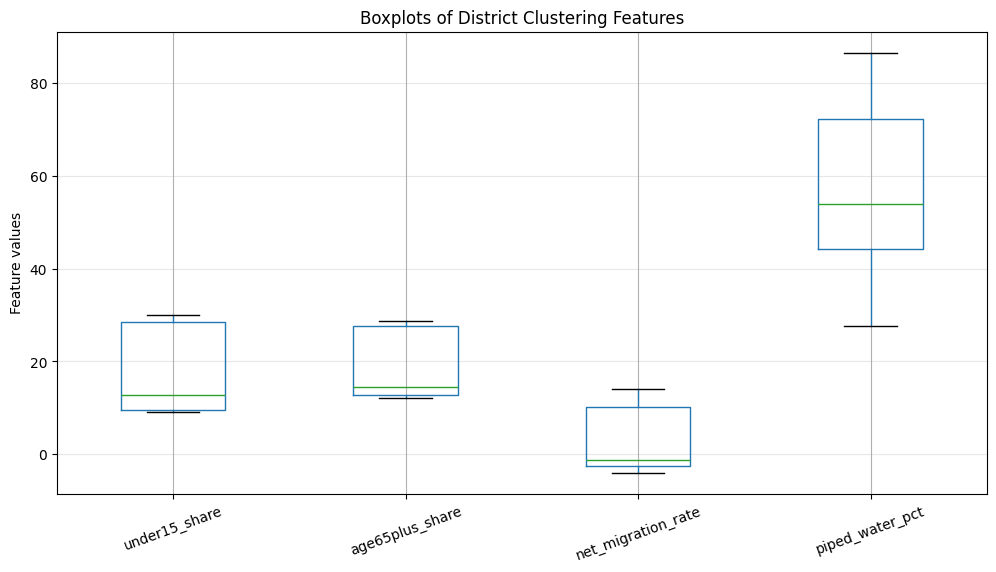

In [30]:
# Summary statistics
print("Summary statistics:")
display(cluster_data[features].describe().round(2))

# Identify districts with missing values
print("\nDistricts with missing values:")
display(
    cluster_data[cluster_data[features].isnull().any(axis=1)]
    [["district_id"] + features]
)

# Plot boxplots to inspect potential outliers
plt.figure(figsize=(12, 6))

cluster_data[features].boxplot()

plt.title("Boxplots of District Clustering Features")
plt.ylabel("Feature values")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()


Impute the missing Values

In [31]:
# Record the missing districts before imputation
missing_districts = cluster_data.loc[
    cluster_data["piped_water_pct"].isnull(),
    "district_id"
].tolist()

# Calculate median using observed water-access values
water_median = cluster_data["piped_water_pct"].median()

# Impute missing values
cluster_data["piped_water_pct"] = (
    cluster_data["piped_water_pct"].fillna(water_median)
)

print("Missing districts:", missing_districts)
print("Median used for imputation:", water_median)

print("\nMissing values after imputation:")
print(cluster_data[features].isnull().sum())

Missing districts: ['D04', 'D17']
Median used for imputation: 54.0

Missing values after imputation:
under15_share         0
age65plus_share       0
net_migration_rate    0
piped_water_pct       0
dtype: int64


Check for outliers in the dataset

In [32]:
# Check potential outliers using IQR
for column in features:

    Q1 = cluster_data[column].quantile(0.25)
    Q3 = cluster_data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = cluster_data[
        (cluster_data[column] < lower) |
        (cluster_data[column] > upper)
    ]

    print(f"\nFeature: {column}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Number of potential outliers:", len(outliers))

    if len(outliers) > 0:
        print("Districts:", outliers["district_id"].tolist())


Feature: under15_share
Lower bound: -18.77
Upper bound: 57.01
Number of potential outliers: 0

Feature: age65plus_share
Lower bound: -9.65
Upper bound: 50.13
Number of potential outliers: 0

Feature: net_migration_rate
Lower bound: -21.48
Upper bound: 29.04
Number of potential outliers: 0

Feature: piped_water_pct
Lower bound: 4.52
Upper bound: 110.93
Number of potential outliers: 0


Standardizing the data

In [33]:
from sklearn.preprocessing import StandardScaler

# Keep district identifiers separate
district_ids = cluster_data["district_id"].copy()

# Standardise the four clustering features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(cluster_data[features])

# Convert back to a DataFrame for inspection
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=district_ids
)

display(X_scaled.head())



,under15_share,age65plus_share,net_migration_rate,piped_water_pct
district_id,,,,
D01,1.429319,-0.545519,-0.776695,-1.459318
D02,-0.450349,-0.872254,1.048312,1.427535
D03,-0.921965,1.413249,-0.718972,0.025182
D04,1.265597,-0.581701,-0.920702,-0.127376
D05,-0.488778,-0.870945,1.709498,1.245640


#### **Explanation and justification**
For the missing values the group agreed to use the medianof the piped water accross the district .

The median have been chosen for imputing missing values because it is not affected by outliers
The other reason why the median has been chosen by the group is because the median can allow us to retain all the 24 district as required by the assignment and it is also a more reasonable measure of central tendency

## **Part 02 :Fitting the model and calculation of scores**
b. Fit k-means for k = 1 to 6 using at least 20 initialisations per fit. Plot WCSS against k and report
percentage reduction between successive candidates. Report mean silhouette for k = 2 to 6 and plot the
individual silhouettes by cluster for two plausible candidates. Explain what WCSS and negative or
near-zero silhouette scores tell you.

#### **Fit K-means for k = 1 to 6**
**The assignment requires:**
- K-means for \(k=1,2,3,4,5,6\).
- At least 20 initialisations per fit.
- WCSS for each candidate.
- Percentage reduction in WCSS between successive values of \(k\).
We'll use 50 initialisations to improve the chance of finding a good clustering solution

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store model results
wcss = []
silhouette_scores = []

k_values = range(1, 7)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=50,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    # Within-cluster sum of squares
    wcss.append(model.inertia_)

    # Silhouette is not defined for k=1
    if k >= 2:
        score = silhouette_score(X_scaled, labels)
        silhouette_scores.append(score)

    print(f"k = {k}")
    print(f"WCSS = {model.inertia_:.4f}")

    if k >= 2:
        print(f"Silhouette score = {score:.4f}")

    print("-" * 35)

k = 1
WCSS = 96.0000
-----------------------------------
k = 2
WCSS = 44.9907
Silhouette score = 0.5585
-----------------------------------
k = 3
WCSS = 5.4710
Silhouette score = 0.8168
-----------------------------------
k = 4
WCSS = 3.4895
Silhouette score = 0.7386
-----------------------------------
k = 5
WCSS = 2.1883
Silhouette score = 0.6294
-----------------------------------
k = 6
WCSS = 1.3203
Silhouette score = 0.6198
-----------------------------------


**Calculate percentage reduction in WCSS**
The formula is:
\[
WCSS Reduction =
\frac{WCSS_{k-1}-WCSS_k}{WCSS_{k-1}}\times100
\]
This measures how much the within-cluster variation decreases when we add another cluster.

In [35]:
wcss_results = pd.DataFrame({
    "k": list(k_values),
    "WCSS": wcss
})

wcss_results["percentage_reduction"] = (
    wcss_results["WCSS"].shift(1) - wcss_results["WCSS"]
) / wcss_results["WCSS"].shift(1) * 100

display(wcss_results.round(4))

,k,WCSS,percentage_reduction
0,1,96.0000,NaN
1,2,44.9907,53.1346
2,3,5.4710,87.8398
3,4,3.4895,36.2177
4,5,2.1883,37.2889
5,6,1.3203,39.6637


**Plot the elbow graph**

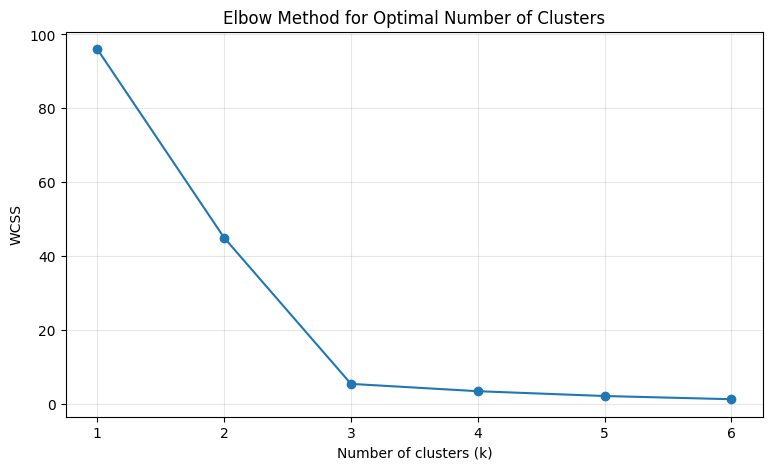

In [36]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

Compare silhouette scores

In [37]:
silhouette_results = pd.DataFrame({
    "k": list(range(2, 7)),
    "mean_silhouette": silhouette_scores
})

display(silhouette_results.round(4))

,k,mean_silhouette
0,2,0.5585
1,3,0.8168
2,4,0.7386
3,5,0.6294
4,6,0.6198


#### **Plot individual silhouettes for two candidates**

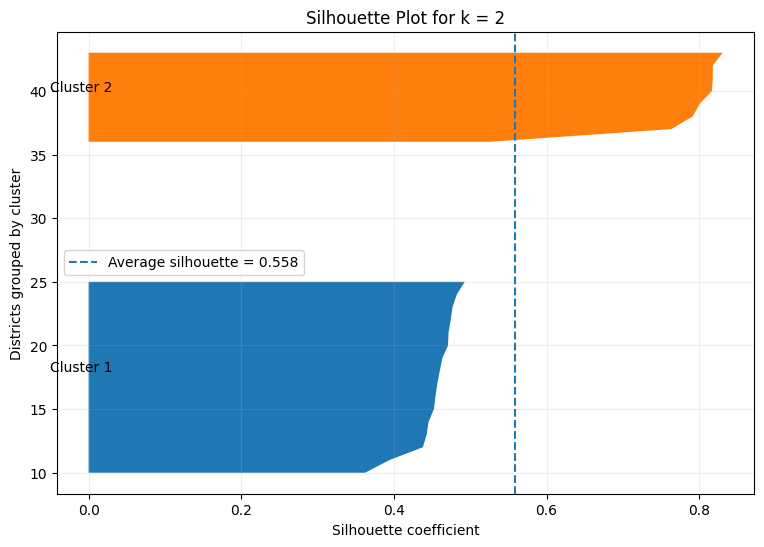

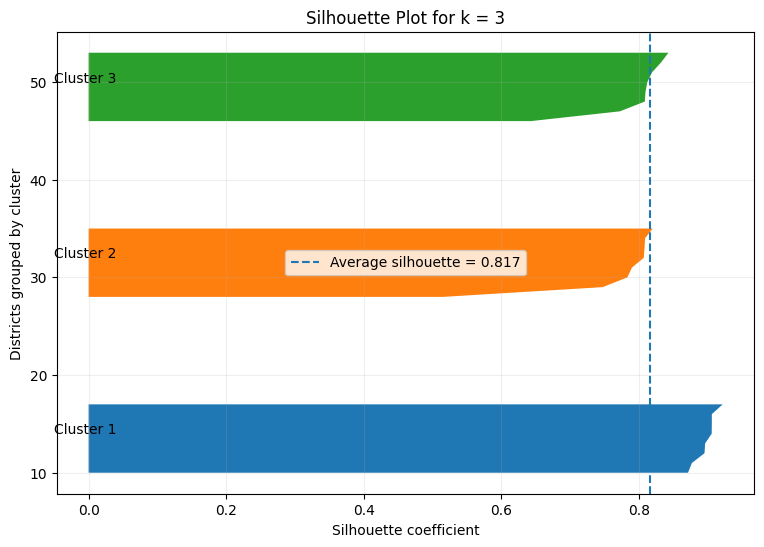

In [38]:
from sklearn.metrics import silhouette_samples
import matplotlib.pyplot as plt

def plot_silhouette(k, X):

    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=42
    )

    labels = model.fit_predict(X)

    sample_silhouette_values = silhouette_samples(X, labels)

    fig, ax = plt.subplots(figsize=(9, 6))

    y_lower = 10

    for cluster in range(k):

        cluster_values = sample_silhouette_values[
            labels == cluster
        ]

        cluster_values.sort()

        size = len(cluster_values)
        y_upper = y_lower + size

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_values
        )

        ax.text(
            -0.05,
            y_lower + size / 2,
            f"Cluster {cluster + 1}"
        )

        y_lower = y_upper + 10

    average_score = sample_silhouette_values.mean()

    ax.axvline(
        average_score,
        linestyle="--",
        label=f"Average silhouette = {average_score:.3f}"
    )

    ax.set_title(f"Silhouette Plot for k = {k}")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Districts grouped by cluster")
    ax.legend()
    ax.grid(alpha=0.2)

    plt.show()


# Compare two candidate solutions
plot_silhouette(2, X_scaled)
plot_silhouette(3, X_scaled)

#### **Comments**

We exclude district_id because it is an identifier, not a demographic measurement. Including it would introduce artificial numerical distances between districts

The other demographic measurements were fit nd transformed under the standard scaler algorithm so that the kmeaans model will not have difficult in clustering the diststrics as there will be no differnt values but all the values will be standardised with a mean 0 and standard deviation of 1

Calculation of WCSSreduction helps to measures how much the within-cluster variation decreases when we add another cluster.

If the sihoulte score is nearer to one it often implies that the districts are perfectly arranged into their respectine clusters so from our analysis we can see that at k =3 there is a higher score making us choose that as our k and we can also see by the fall that happennedd  there that more information was learned on that .

**Below are the interpretaion of the silhouette score which ranges from -1 to 1**

Close to +1	Districts are well matched to their own clusters and separated from others.
Around 0	Clusters overlap or districts lie near cluster boundaries.
Negative	Some districts may be assigned to the wrong cluster

## **Part 3:Justifying the chosen k(k =3)**
Justify your chosen k using both diagnostics and demographic meaning. Check stability under a
different seed and one reasonable change to feature selection or missing-value treatment. Compare
district memberships allowing for renamed labels, or use an adjusted Rand index on common districts.

#### **Running codes that can help establish a bold conclusion on using k =3**

Establish the primary clustering solution

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

# Primary model: k=3, random_state=42
primary_model = KMeans(
    n_clusters=3,
    n_init=50,
    random_state=42
)

primary_labels = primary_model.fit_predict(X_scaled)

# Save primary cluster memberships
cluster_data["primary_cluster"] = primary_labels

print("Primary cluster sizes:")
print(cluster_data["primary_cluster"].value_counts().sort_index())
print("\nPrimary cluster memberships:")

display(
    cluster_data[
        ["district_id", "primary_cluster"]
    ].sort_values("primary_cluster")
)


Primary cluster sizes:
primary_cluster
0    8
1    8
2    8
Name: count, dtype: int64

Primary cluster memberships:


,district_id,primary_cluster
2,D03,0
5,D06,0
11,D12,0
8,D09,0
14,D15,0
23,D24,0
20,D21,0
17,D18,0
13,D14,1
10,D11,1


Test stability using a different random seed

In [40]:
# Fit another K-means model with a different random seed
second_model = KMeans(
    n_clusters=3,
    n_init=50,
    random_state=99
)

second_labels = second_model.fit_predict(X_scaled)

# Compare the two solutions
seed_ari = adjusted_rand_score(
    primary_labels,
    second_labels
)

print("Adjusted Rand Index (different seed):", round(seed_ari, 4))

# Display memberships side by side
seed_comparison = pd.DataFrame({
    "district_id": cluster_data["district_id"],
    "seed_42": primary_labels,
    "seed_99": second_labels
})

display(seed_comparison.sort_values("seed_42"))

Adjusted Rand Index (different seed): 1.0


,district_id,seed_42,seed_99
2,D03,0,2
5,D06,0,2
11,D12,0,2
8,D09,0,2
14,D15,0,2
23,D24,0,2
20,D21,0,2
17,D18,0,2
13,D14,1,0
10,D11,1,0


Test sensitivity to missing-value treatment

In [41]:
# Create an alternative dataset
cluster_data_alt = cluster_data.copy()

# Restore missing values in the two original districts
cluster_data_alt.loc[
    cluster_data_alt["district_id"].isin(missing_districts),
    "piped_water_pct"
] = np.nan

# Apply mean imputation
water_mean = cluster_data_alt["piped_water_pct"].mean()

cluster_data_alt["piped_water_pct"] = (
    cluster_data_alt["piped_water_pct"].fillna(water_mean)
)

print("Mean used for alternative imputation:", round(water_mean, 2))

# Standardise alternative features
alternative_scaler = StandardScaler()

X_alt = alternative_scaler.fit_transform(
    cluster_data_alt[features]
)

# Fit alternative K-means model
alternative_model = KMeans(
    n_clusters=3,
    n_init=50,
    random_state=42
)

alternative_labels = alternative_model.fit_predict(X_alt)

# Compare alternative clustering with primary clustering
imputation_ari = adjusted_rand_score(
    primary_labels,
    alternative_labels
)

print("Adjusted Rand Index (alternative imputation):",
      round(imputation_ari, 4))

# Compare district memberships
imputation_comparison = pd.DataFrame({
    "district_id": cluster_data["district_id"],
    "median_imputation": primary_labels,
    "mean_imputation": alternative_labels
})

display(imputation_comparison.sort_values("median_imputation"))

Mean used for alternative imputation: 56.37
Adjusted Rand Index (alternative imputation): 1.0


,district_id,median_imputation,mean_imputation
2,D03,0,0
5,D06,0,0
11,D12,0,0
8,D09,0,0
14,D15,0,0
23,D24,0,0
20,D21,0,0
17,D18,0,0
13,D14,1,1
10,D11,1,1


Examine the demographic meaning of the clusters

In [42]:
# Calculate average demographic characteristics
cluster_profiles = (
    cluster_data.groupby("primary_cluster")[features]
    .mean()
)

print("Average characteristics of each cluster:")
display(cluster_profiles.round(2))

print("\nNumber of districts per cluster:")
print(
    cluster_data["primary_cluster"]
    .value_counts()
    .sort_index()
)

Average characteristics of each cluster:


,under15_share,age65plus_share,net_migration_rate,piped_water_pct
primary_cluster,,,,
0,9.49,27.89,-1.53,53.79
1,12.90,12.56,12.01,75.97
2,28.97,14.59,-2.77,38.75



Number of districts per cluster:
primary_cluster
0    8
1    8
2    8
Name: count, dtype: int64


## **Comment**
The three-cluster solution was selected based on the combined evidence from the elbow method, WCSS reductions and silhouette analysis. The WCSS decreased by 87.84% when moving from two to three clusters, while the mean silhouette score reached its maximum of 0.8168 at three clusters. This indicates strong separation between the resulting groups.

The three clusters revealed distinct demographic characteristics. Cluster 0 represents ageing districts, characterised by a high proportion of residents aged 65 and above. Cluster 1 represents districts experiencing substantial net migration inflows and relatively high piped-water access. Cluster 2 consists of younger districts with higher proportions of children and lower piped-water access.

The solution was also stable under alternative modelling choices. Changing the random seed produced identical district memberships after accounting for different cluster labels. Similarly, replacing median imputation with mean imputation resulted in an Adjusted Rand Index of 1.00. These findings demonstrate that the clustering structure is robust to the tested changes.

In [43]:
cluster_data.to_csv('../outputs/clustering/district_clusters.csv')
cluster=cluster_data[
        ["district_id", "primary_cluster"]
    ].sort_values("primary_cluster")

cluster.to_csv('../outputs/clustering/clusters.csv')
cluster_profiles.to_csv('../outputs/clustering/cluster_profiles.csv')